In [1]:
import duckdb

duckdb.sql("SELECT * FROM 'hmrc_oil_imports.csv' LIMIT 10").df()

,MonthId,FlowTypeId,SuppressionIndex,CommodityId,CommoditySitcId,CountryId,PortId,Value,NetMass,SuppUnit
0,201909,1,0,27090010,33300,1,0,18943.0,1.0,0.0
1,201901,1,0,27090010,33300,3,0,1003694.0,3726784.0,0.0
2,201902,1,0,27090010,33300,3,0,0.0,0.0,0.0
3,201903,1,0,27090010,33300,3,0,1222417.0,4528153.0,0.0
4,201904,1,0,27090010,33300,3,0,1227098.0,4545291.0,0.0
5,201905,1,0,27090010,33300,3,0,1193126.0,4420890.0,0.0
6,201906,1,0,27090010,33300,3,0,1227408.0,4546427.0,0.0
7,201907,1,0,27090010,33300,3,0,1226705.0,4543849.0,0.0
8,201908,1,0,27090010,33300,3,0,978117.0,3633008.0,0.0
9,201910,1,0,27090010,33300,3,0,1197544.0,4437069.0,0.0


In [2]:
import requests
import pandas as pd

countries = pd.DataFrame(requests.get("https://api.uktradeinfo.com/Country", timeout=60).json()["value"])
countries.to_csv("hmrc_countries.csv", index=False)
countries.head(10)

,CountryId,CountryCodeNumeric,RegionId,CountryName,CountryCodeAlpha,Area1,Area2,Area3,Area4,Area5,Area1a,Area2a,Area3a,Area4a,Area5a
0,1,001,001,France,FR,1,,,,,European Union,,,,
1,3,003,001,Netherlands,NL,1,,,,,European Union,,,,
2,4,004,001,Germany,DE,1,,,,,European Union,,,,
3,5,005,001,Italy,IT,1,,,,,European Union,,,,
4,6,006,000,UK,GB,1,,,,,European Union,,,,
5,7,007,001,Ireland,IE,1,,,,,European Union,,,,
6,8,008,001,Denmark,DK,1,,,,,European Union,,,,
7,9,009,001,Greece,GR,1,,,,,European Union,,,,
8,10,010,001,Portugal,PT,1,,,,,European Union,,,,
9,11,011,001,Spain,ES,1,,,,,European Union,,,,


In [3]:
duckdb.sql("""
    SELECT c.CountryName,
           ROUND(SUM(t.Value) / 1e9, 2) AS value_bn
    FROM 'hmrc_oil_imports.csv' AS t
    JOIN 'hmrc_countries.csv' AS c ON t.CountryId = c.CountryId
    GROUP BY c.CountryName
    ORDER BY value_bn DESC
    LIMIT 10
""").df()

,CountryName,value_bn
0,Norway,75.41
1,United States,63.33
2,Netherlands,32.44
3,Belgium,14.57
4,Russia,11.93
5,Kuwait,11.68
6,Saudi Arabia,9.76
7,Nigeria,9.64
8,Libya,9.00
9,Algeria,8.77


In [4]:
duckdb.sql("""
    SELECT LEFT(CAST(t.MonthId AS VARCHAR), 4) AS year,
           ROUND(SUM(t.Value) / 1e9, 2) AS value_bn
    FROM 'hmrc_oil_imports.csv' AS t
    JOIN 'hmrc_countries.csv' AS c ON t.CountryId = c.CountryId
    WHERE c.CountryName = 'Russia'
    GROUP BY year
    ORDER BY year
""").df()

,year,value_bn
0,2019,4.64
1,2020,2.48
2,2021,3.27
3,2022,1.53


In [5]:
duckdb.sql("""
    SELECT LEFT(CAST(t.MonthId AS VARCHAR), 4) AS year,
           ROUND(SUM(t.Value) / 1e9, 2) AS value_bn
    FROM 'hmrc_oil_imports.csv' AS t
    JOIN 'hmrc_countries.csv' AS c ON t.CountryId = c.CountryId
    WHERE c.CountryName = 'Russia'
    GROUP BY year
    ORDER BY year
""").df()

,year,value_bn
0,2019,4.64
1,2020,2.48
2,2021,3.27
3,2022,1.53


In [6]:
duckdb.sql("""
    SELECT c.CountryName,
           ROUND(SUM(CASE WHEN t.MonthId BETWEEN 201901 AND 202112 THEN t.Value END) / 3e9, 2) AS before_bn_per_year,
           ROUND(SUM(CASE WHEN t.MonthId BETWEEN 202301 AND 202512 THEN t.Value END) / 3e9, 2) AS after_bn_per_year
    FROM 'hmrc_oil_imports.csv' AS t
    JOIN 'hmrc_countries.csv' AS c ON t.CountryId = c.CountryId
    GROUP BY c.CountryName
    ORDER BY after_bn_per_year DESC NULLS LAST
    LIMIT 15
""").df()

,CountryName,before_bn_per_year,after_bn_per_year
0,United States,4.40,10.10
1,Norway,8.01,9.71
2,Netherlands,1.85,5.12
3,Kuwait,0.40,2.59
4,Belgium,0.89,2.23
5,Libya,0.46,1.77
6,Nigeria,1.04,1.28
7,UAE,0.59,1.19
8,Algeria,0.97,1.15
9,Saudi Arabia,1.07,1.14


In [7]:
duckdb.sql("""
    SELECT c.CountryName,
           ROUND(SUM(CASE WHEN t.MonthId BETWEEN 201901 AND 202112 THEN t.NetMass END) / 3e9, 2) AS before_mt_per_year,
           ROUND(SUM(CASE WHEN t.MonthId BETWEEN 202301 AND 202512 THEN t.NetMass END) / 3e9, 2) AS after_mt_per_year
    FROM 'hmrc_oil_imports.csv' AS t
    JOIN 'hmrc_countries.csv' AS c ON t.CountryId = c.CountryId
    GROUP BY c.CountryName
    ORDER BY after_mt_per_year DESC NULLS LAST
    LIMIT 15
""").df()

,CountryName,before_mt_per_year,after_mt_per_year
0,Norway,23.21,20.81
1,United States,12.32,19.26
2,Netherlands,4.35,7.76
3,Kuwait,0.97,4.08
4,Libya,1.24,3.75
5,Belgium,1.88,3.36
6,Nigeria,2.89,2.53
7,Algeria,2.47,2.40
8,UAE,1.37,1.87
9,Saudi Arabia,2.53,1.74


In [8]:
duckdb.sql("""
    SELECT c.CountryName,
           CASE WHEN LEFT(CAST(t.CommodityId AS VARCHAR), 4) = '2709' THEN 'Crude oil'
                ELSE 'Refined fuels' END AS product,
           ROUND(SUM(t.NetMass) / 3e9, 2) AS mt_per_year,
           ROUND(SUM(t.Value) / SUM(t.NetMass) * 1000, 0) AS gbp_per_tonne
    FROM 'hmrc_oil_imports.csv' AS t
    JOIN 'hmrc_countries.csv' AS c ON t.CountryId = c.CountryId
    WHERE t.MonthId BETWEEN 202301 AND 202512
      AND c.CountryName IN ('Norway', 'United States')
    GROUP BY c.CountryName, product
    ORDER BY c.CountryName, product
""").df()

,CountryName,product,mt_per_year,gbp_per_tonne
0,Norway,Crude oil,20.01,459.0
1,Norway,Refined fuels,0.80,640.0
2,United States,Crude oil,15.20,489.0
3,United States,Refined fuels,4.06,656.0


In [9]:
duckdb.sql("""
    SELECT
        COUNT(*) AS total_rows,
        SUM(CASE WHEN NetMass = 0 THEN 1 ELSE 0 END) AS zero_weight,
        SUM(CASE WHEN NetMass > 0 AND NetMass < 1000 THEN 1 ELSE 0 END) AS under_1_tonne,
        SUM(CASE WHEN Value = 0 THEN 1 ELSE 0 END) AS zero_value,
        SUM(CASE WHEN SuppressionIndex <> 0 THEN 1 ELSE 0 END) AS suppressed
    FROM 'hmrc_oil_imports.csv'
""").df()

,total_rows,zero_weight,under_1_tonne,zero_value,suppressed
0,48541,117.0,14261.0,62.0,0.0


In [10]:
duckdb.sql("""
    SELECT
        CASE WHEN NetMass = 0 THEN 'Zero weight'
             WHEN NetMass < 1000 THEN 'Under 1 tonne'
             ELSE '1 tonne or more' END AS row_type,
        COUNT(*) AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_rows,
        ROUND(100.0 * SUM(Value) / SUM(SUM(Value)) OVER (), 3) AS pct_of_value,
        ROUND(100.0 * SUM(NetMass) / SUM(SUM(NetMass)) OVER (), 3) AS pct_of_weight
    FROM 'hmrc_oil_imports.csv'
    GROUP BY row_type
    ORDER BY rows DESC
""").df()

,row_type,rows,pct_of_rows,pct_of_value,pct_of_weight
0,1 tonne or more,34163,70.4,99.977,99.999
1,Under 1 tonne,14261,29.4,0.023,0.001
2,Zero weight,117,0.2,0.000,0.000


## Data quality check: small and zero-weight rows

29.4% of rows are under 1 tonne, and 0.2% have zero weight. Together they make up only 0.023% of value and 0.001% of weight.
They are likely genuine small shipments (for example, lubricants in drums), so I have kept them. They do not affect the findings.

In [11]:
monthly = duckdb.sql("""
    WITH monthly_country AS (
        SELECT MonthId, CountryId, SUM(NetMass) AS tonnes
        FROM 'hmrc_oil_imports.csv'
        WHERE LEFT(CAST(CommodityId AS VARCHAR), 4) = '2709'
        GROUP BY MonthId, CountryId
    ),
    shares AS (
        SELECT MonthId,
               tonnes / SUM(tonnes) OVER (PARTITION BY MonthId) AS share
        FROM monthly_country
        WHERE tonnes > 0
    )
    SELECT MonthId,
           ROUND(EXP(-SUM(share * LN(share))), 2) AS effective_suppliers
    FROM shares
    GROUP BY MonthId
    ORDER BY MonthId
""").df()

monthly

,MonthId,effective_suppliers
0,201901,4.50
1,201902,4.75
2,201903,4.36
3,201904,3.93
4,201905,5.06
...,...,...
88,202605,4.74
89,202606,3.83
90,202607,5.24
91,202608,5.08


In [12]:
duckdb.sql("""
    SELECT LEFT(CAST(MonthId AS VARCHAR), 4) AS year,
           ROUND(AVG(effective_suppliers), 2) AS average,
           MIN(effective_suppliers) AS lowest,
           MAX(effective_suppliers) AS highest,
           ROUND(STDDEV(effective_suppliers), 2) AS std_dev
    FROM monthly
    GROUP BY year
    ORDER BY year
""").df()

,year,average,lowest,highest,std_dev
0,2019,4.62,3.91,5.60,0.58
1,2020,4.27,3.55,5.30,0.42
2,2021,4.12,3.44,5.03,0.47
3,2022,4.66,3.24,5.87,0.85
4,2023,4.52,3.79,5.53,0.51
5,2024,4.60,3.66,5.42,0.50
6,2025,4.96,4.22,6.09,0.61
7,2026,4.47,3.06,5.24,0.67


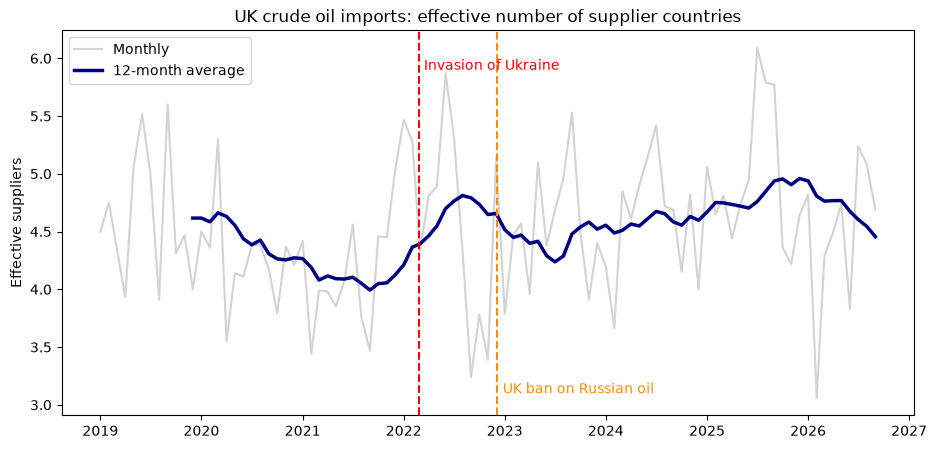

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Turn 201901 into a real date
monthly["date"] = pd.to_datetime(monthly["MonthId"].astype(str), format="%Y%m")

# 12-month rolling average to smooth out the month-to-month noise
monthly["rolling_12m"] = monthly["effective_suppliers"].rolling(12).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly["date"], monthly["effective_suppliers"], color="lightgrey", label="Monthly")
ax.plot(monthly["date"], monthly["rolling_12m"], color="navy", linewidth=2.5, label="12-month average")

# Mark the key events
ax.axvline(pd.Timestamp("2022-02-24"), color="red", linestyle="--")
ax.text(pd.Timestamp("2022-03-15"), 5.9, "Invasion of Ukraine", color="red")
ax.axvline(pd.Timestamp("2022-12-05"), color="darkorange", linestyle="--")
ax.text(pd.Timestamp("2022-12-25"), 3.1, "UK ban on Russian oil", color="darkorange")

ax.set_title("UK crude oil imports: effective number of supplier countries")
ax.set_ylabel("Effective suppliers")
ax.legend()
plt.show()